# Phase 1 (Gemini): baseline pass^k curve

**Why Gemini:** the project requirements call for Gemini, like the paper "τ-bench: A Benchmark for Tool-Agent-User Interaction in Real-World Domains" (Yao et al., 2024).

**Backend** (`BACKEND` in `settings_gemini.py`): `"apikey"` uses my Gemini API key from Colab Secrets (name `GEMINI_API_KEY`). `"colab"` uses Colab's built-in Gemini: no key, but its quota ran out after about 20 dialogues. Both support tool calling, which τ-bench needs.

**Model:** `gemini-3.1-flash-lite` for both the agent and the user simulator (set in `settings_gemini.py`), a low-cost Gemini. The paper's `gemini-1.5-flash` is retired, and `gemini-2.5-flash-lite` is closed to new users. Thinking is left at the model's default for both.

**Cost:** paid Gemini API (prepaid credits, auto-reload off). One arm (400 dialogues) cost about $8.

**Runtime:** CPU only. Runtime → Change runtime type → **CPU**. Do not use a GPU here.

**Run:** first a 10-task pilot to measure pass rate, calls, tokens and cost. Then all 50 tasks × 8 trials = 400 dialogues, one folder per trial.

**Safe to stop:** finished tasks are skipped. If the credits run out, the run stops; add credits, run the cell again, and it continues.

**Follows the τ-bench paper, so my numbers can be compared with its Table 2:**

| Setting | Paper | Mine |
|---|---|---|
| Code, domain, tasks | official τ-bench, airline, 50 test tasks | same |
| Agent | function calling (tool-calling) | same |
| Max agent actions | 30 | same (τ-bench default) |
| Agent / user temperature | 0.0 / 1.0 | same |
| Score | final database state (+ outputs) | same |
| pass^1, pass^k | mean reward; C(c,k)/C(n,k) | same (`passk.py`) |
| Trials per task | at least 3 | 8 |
| Agent model | gemini-1.5-flash (retired) | gemini-3.1-flash-lite |
| User model | gpt-4-0613 | gemini-3.1-flash-lite (no paid OpenAI access) |

The paper's airline pass^1 for gemini-1.5-flash is 26.0, for gpt-4o 35.2. **Mine: 0.525** (see the Summary at the end).

In [ ]:
# mount Google Drive so results are saved
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
# go into the repo and install tau-bench (CPU runtime, no vLLM needed)
%cd /content/drive/MyDrive/cmsc691-10-project2
!pip install -q -e .
!pip install -q mcp
print("installed")

/content/drive/MyDrive/cmsc691-10-project2
  Installing build dependencies ... done
  Checking if build backend supports build_editable ... done
  Getting requirements to build editable ... done
  Preparing editable metadata (pyproject.toml) ... done
  Building editable for tau_bench (pyproject.toml) ... done
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-cloud-dataproc 5.32.0 requires protobuf<8.0.0,>=6.33.5, but you have protobuf 5.29.6 which is incompatible.
google-cloud-bigquery-storage 2.43.0 requires protobuf<8.0.0,>=6.33.5, but you have protobuf 5.29.6 which is incompatible.
google-cloud-resource-manager 1.19.0 requires protobuf<8.0.0,>=6.33.5, but you have protobuf 5.29.6 which is incompatible.
google-cloud-bigquery-connection 1.23.0 requires protobuf<8.0.0,>=6.33.5, but you have protobuf 5.29.6 which is incompatible.
tensorflow 2.21.0 requires 

In [ ]:
%%writefile /content/drive/MyDrive/cmsc691-10-project2/settings_gemini.py
# frozen settings for every Gemini arm (baseline, validator, shallow, semi-deep)
# no GPU needed: the model runs on Google's side
BACKEND = "apikey"                  # "apikey": my Gemini API key (Colab Secret GEMINI_API_KEY)
                                    # "colab": Colab's built-in Gemini (small quota, ran out)
MODEL = "gemini-3.1-flash-lite"     # agent and user simulator, same model (cheap Gemini; 2.5-flash-lite is closed to new users)
PRICE_IN, PRICE_OUT = 0.25, 1.50    # USD per 1M tokens for MODEL, from the Gemini price list; for cost estimates only
PROXY_PREFIX = "google/"            # only for "colab": it wants "google/<model>"; tau-bench file names can't have "/"
TEMPERATURE = 0.0                   # agent temperature, same as the tau-bench paper
USER_TEMPERATURE = 1.0              # user simulator temperature, same as the tau-bench paper
CONCURRENCY = 4                     # dialogues at once; Gemini runs on Google's side, so this doesn't change results
NUM_RETRIES = 6                     # retry a call after a rate-limit error
CALL_TIMEOUT = 600                  # seconds per model call
ENV = "airline"
N_TASKS = 50
N_TRIALS = 8

Overwriting /content/drive/MyDrive/cmsc691-10-project2/settings_gemini.py


In [ ]:
%%writefile /content/drive/MyDrive/cmsc691-10-project2/gemini_run.py
# run tau-bench on Gemini: with my API key, or Colab's built-in Gemini
# every model call goes through logged(): it picks the backend,
# retries on rate limits, and writes tokens and seconds to a .jsonl file
import json
import os
import sys
import threading
import time

import litellm
from settings_gemini import NUM_RETRIES, CALL_TIMEOUT, PROXY_PREFIX, USER_TEMPERATURE, BACKEND

litellm.suppress_debug_info = True
if BACKEND == "colab":
    BASE = os.environ["COLAB_PROXY_BASE"]  # set by the notebook from google.colab.ai
    KEY = os.environ["COLAB_PROXY_KEY"]
else:
    KEY = os.environ["GEMINI_API_KEY"]     # set by the notebook from Colab Secrets
LOG = os.environ.get("CALL_LOG", "gemini_calls.jsonl")
_lock = threading.Lock()
_real = litellm.completion


def logged(*args, **kwargs):
    who = "agent" if kwargs.get("tools") else "user"
    if BACKEND == "colab":
        m = kwargs.get("model", "")
        if not m.startswith(PROXY_PREFIX):
            kwargs["model"] = PROXY_PREFIX + m
        kwargs["custom_llm_provider"] = "openai"
        kwargs["api_base"] = BASE
    else:
        kwargs["custom_llm_provider"] = "gemini"
    kwargs["api_key"] = KEY
    if who == "user":
        # tau-bench paper: "temperature is 0.0 for agent and 1.0 for user".
        # tau-bench's code sends no temperature for the user, so I set it here.
        kwargs["temperature"] = USER_TEMPERATURE
    kwargs.setdefault("num_retries", NUM_RETRIES)
    kwargs["timeout"] = CALL_TIMEOUT
    t0 = time.time()
    res = _real(*args, **kwargs)
    u = res.usage
    details = getattr(u, "completion_tokens_details", None)
    row = {"who": who, "sec": round(time.time() - t0, 2),
           "prompt": u.prompt_tokens, "completion": u.completion_tokens,
           "reasoning": getattr(details, "reasoning_tokens", None) or 0}
    with _lock, open(LOG, "a") as f:
        f.write(json.dumps(row) + "\n")
    # an empty reply crashes tau-bench's scoring; make it "" (a normal fail)
    msg = res.choices[0].message
    if msg.content is None and not msg.tool_calls:
        msg.content = ""
    return res


# patch BEFORE tau-bench imports completion, and patch the user module too
# (it keeps its own copy: the bug I hit in 06)
litellm.completion = logged
import tau_bench.envs.user as _user
_user.completion = lambda *a, **k: litellm.completion(*a, **k)

sys.argv[0] = "run.py"
from run import main
main()

Overwriting /content/drive/MyDrive/cmsc691-10-project2/gemini_run.py


In [ ]:
# load settings, connect to Gemini (API key or Colab), and check tool calling once
import os, sys, re, importlib, logging, warnings
import pandas as pd
from IPython.display import display
sys.path.insert(0, "/content/drive/MyDrive/cmsc691-10-project2")
importlib.invalidate_caches()
import settings_gemini; importlib.reload(settings_gemini)
from settings_gemini import *
warnings.filterwarnings("ignore")
logging.getLogger("LiteLLM").setLevel(logging.ERROR)   # hide litellm's long warnings

def short_error(e):
    # keep only the API's own message, one line
    m = re.search(r'"message":\s*"([^"]+)"', str(e))
    return (m.group(1) if m else str(e).splitlines()[0])[:200]

def set_token():
    if BACKEND == "colab":
        # the Colab token can expire, so I get a fresh one before each run
        from google.colab import ai
        os.environ["COLAB_PROXY_BASE"] = f"{ai._get_model_proxy_host()}/models/openapi"
        os.environ["COLAB_PROXY_KEY"] = ai._get_model_proxy_token()
    else:
        # my key from Colab Secrets (name GEMINI_API_KEY); never printed
        from google.colab import userdata
        os.environ["GEMINI_API_KEY"] = userdata.get("GEMINI_API_KEY")
set_token()

display(pd.DataFrame({"setting": [k for k in vars(settings_gemini) if k.isupper()],
                       "value": [vars(settings_gemini)[k] for k in vars(settings_gemini) if k.isupper()]})
        .set_index("setting").T)

import litellm
litellm.suppress_debug_info = True
tools = [{"type": "function", "function": {
    "name": "get_reservation", "description": "Look up a reservation",
    "parameters": {"type": "object", "properties": {"reservation_id": {"type": "string"}},
                   "required": ["reservation_id"]}}}]
if BACKEND == "colab":
    kw = dict(model=PROXY_PREFIX + MODEL, custom_llm_provider="openai",
              api_base=os.environ["COLAB_PROXY_BASE"], api_key=os.environ["COLAB_PROXY_KEY"])
else:
    kw = dict(model=MODEL, custom_llm_provider="gemini", api_key=os.environ["GEMINI_API_KEY"])
try:
    r = litellm.completion(**kw, temperature=0.0, tools=tools,
                           messages=[{"role": "user", "content": "Look up reservation ABC123."}])
    ok = bool(r.choices[0].message.tool_calls)
    print(f"{'✅ tool call works' if ok else '❌ no tool call'} | model {MODEL}")
except Exception as e:
    print(f"❌ {type(e).__name__}: {short_error(e)}")
    print("Fix MODEL in cell 3 (%%writefile settings_gemini.py), run cell 3, then this cell again.")

setting,BACKEND,MODEL,PRICE_IN,PRICE_OUT,PROXY_PREFIX,TEMPERATURE,USER_TEMPERATURE,CONCURRENCY,NUM_RETRIES,CALL_TIMEOUT,ENV,N_TASKS,N_TRIALS
value,apikey,gemini-3.1-flash-lite,0.25,1.5,google/,0.0,1.0,4,6,600,airline,50,8


✅ tool call works | model gemini-3.1-flash-lite


In [ ]:
# pilot: 10 tasks, 1 trial. Measures calls, tokens, cost and pass rate before the full run
import time, json
%cd /content/drive/MyDrive/cmsc691-10-project2
PILOT = "results_gemini_pilot"
PILOT_TASKS = list(range(10))
os.makedirs(PILOT, exist_ok=True)
os.environ["CALL_LOG"] = f"{PILOT}/calls.jsonl"
set_token()
t0 = time.time()
ids = " ".join(map(str, PILOT_TASKS))
!python gemini_run.py --env {ENV} --agent-strategy tool-calling \
  --model {MODEL} --model-provider openai \
  --user-model {MODEL} --user-model-provider openai \
  --user-strategy llm --num-trials 1 --temperature {TEMPERATURE} \
  --task-ids {ids} --max-concurrency {CONCURRENCY} \
  --log-dir {PILOT} 2>&1 | tail -n 6
print(f"{(time.time() - t0) / 60:.1f} min for {len(PILOT_TASKS)} tasks")

/content/drive/MyDrive/cmsc691-10-project2
14:25:55 - LiteLLM:WARNING: vertex_and_google_ai_studio_gemini.py:1152 - DeprecationWarning: `temperature`, `top_p`, and `top_k` continue to function for Gemini 3+ (gemini-3.1-flash-lite) but are planned for removal in a future release. Move sampling guidance into the `system` instructions instead.
14:25:56 - LiteLLM:WARNING: vertex_and_google_ai_studio_gemini.py:1152 - DeprecationWarning: `temperature`, `top_p`, and `top_k` continue to function for Gemini 3+ (gemini-3.1-flash-lite) but are planned for removal in a future release. Move sampling guidance into the `system` instructions instead.
14:28:06 - LiteLLM:WARNING: vertex_and_google_ai_studio_gemini.py:1152 - DeprecationWarning: `temperature`, `top_p`, and `top_k` continue to function for Gemini 3+ (gemini-3.1-flash-lite) but are planned for removal in a future release. Move sampling guidance into the `system` instructions instead.
14:28:07 - LiteLLM:WARNING: vertex_and_google_ai_studio_g

In [ ]:
# pilot result: pass rate, API errors, cost, and what the full run (400 dialogues) would cost
import pandas as pd, importlib, passk; importlib.reload(passk)
from IPython.display import display
rows = passk.load_trial("/content/drive/MyDrive/cmsc691-10-project2/results_gemini_pilot")
errs = [r for r in rows.values() if passk.is_error(r)]
ok = [r for r in rows.values() if not passk.is_error(r)]
passed = sum(r["reward"] >= 1 - 1e-6 for r in ok)
calls = pd.read_json("/content/drive/MyDrive/cmsc691-10-project2/results_gemini_pilot/calls.jsonl", lines=True)
n = max(len(ok), 1)
tin, tout = calls.prompt.sum(), calls.completion.sum()
cost = tin / 1e6 * PRICE_IN + tout / 1e6 * PRICE_OUT
display(pd.DataFrame([{
    "model": MODEL, "tasks": len(rows), "API errors": len(errs),
    "passed": f"{passed}/{len(ok)}", "pass rate": round(passed / n, 2),
    "calls / dialogue": round(len(calls) / n), "input k-tok / dialogue": round(tin / n / 1e3),
    "output k-tok / dialogue": round(tout / n / 1e3, 1),
    "pilot cost $": round(cost, 2), "one arm (400) $": round(cost / n * 400, 2)}]).T.rename(columns={0: ""}))
for r in errs[:3]:
    print(f"error task {r['task_id']}: {short_error(r['info']['error'])}")
print("Go on to the full run (cell 8) only if: API errors = 0 and the pass rate is not near 0.")

,
model,gemini-3.1-flash-lite
tasks,10
API errors,0
passed,5/10
pass rate,0.5
calls / dialogue,58
input k-tok / dialogue,285
output k-tok / dialogue,5.0
pilot cost $,0.79
one arm (400) $,31.56


Go on to the full run (cell 8) only if: API errors = 0 and the pass rate is not near 0.


In [ ]:
# run the Gemini baseline: 8 trials, one folder each, skip what is done
import os, sys, time, json, importlib
sys.path.insert(0, "/content/drive/MyDrive/cmsc691-10-project2")
importlib.invalidate_caches()
import passk; importlib.reload(passk)

%cd /content/drive/MyDrive/cmsc691-10-project2
OUT = "results_gemini_baseline"
LOGS = "/content/drive/MyDrive/cmsc691-10-project2/logs_gemini"
os.makedirs(LOGS, exist_ok=True)
json.dump({**{k: v for k, v in vars(settings_gemini).items() if k.isupper()},
          "policy": "prose wiki.md",
          "backend": "Colab built-in Gemini" if BACKEND == "colab" else "paid Gemini API (AI Studio key)"},
          open(f"{OUT}_config.json", "w"), indent=2)

start_all = time.time()
for trial in range(1, N_TRIALS + 1):
    folder = f"{OUT}/trial_{trial}"
    os.makedirs(folder, exist_ok=True)
    todo = sorted(set(range(N_TASKS)) - passk.done_tasks(folder))
    if not todo:
        print(f"trial {trial}: done, skip")
        continue
    print(f"trial {trial}: running {len(todo)} tasks ...", end=" ", flush=True)
    t0 = time.time()
    ids = " ".join(map(str, todo))
    set_token()
    os.environ["CALL_LOG"] = f"{folder}/calls.jsonl"
    log = f"{LOGS}/baseline_trial_{trial}.log"
    !echo "===== run at $(date) =====" >> {log}
    !python gemini_run.py --env {ENV} --agent-strategy tool-calling \
      --model {MODEL} --model-provider openai \
      --user-model {MODEL} --user-model-provider openai \
      --user-strategy llm --num-trials 1 --temperature {TEMPERATURE} \
      --task-ids {ids} --max-concurrency {CONCURRENCY} \
      --log-dir {folder} >> {log} 2>&1
    left = N_TASKS - len(passk.done_tasks(folder))
    print(f"{(time.time() - t0) / 60:.1f} min, {left} not done")
print(f"\nall trials: {(time.time() - start_all) / 60:.1f} min this session")

/content/drive/MyDrive/cmsc691-10-project2
trial 1: done, skip
trial 2: running 5 tasks ... 0.5 min, 0 not done
trial 3: running 50 tasks ... 5.0 min, 0 not done
trial 4: running 50 tasks ... 8.8 min, 0 not done
trial 5: running 50 tasks ... 42.5 min, 0 not done
trial 6: running 50 tasks ... 5.7 min, 0 not done
trial 7: running 50 tasks ... 30.1 min, 0 not done
trial 8: running 50 tasks ... 4.7 min, 0 not done

all trials: 97.3 min this session


In [ ]:
# move old gemini-3.5-flash result files (free-key test) out of the baseline folder
import glob, json, os, shutil
R = "/content/drive/MyDrive/cmsc691-10-project2"
for f in sorted(glob.glob(f"{R}/results_gemini_baseline/trial_*/*gemini-3.5-flash*.json")):
    rows = json.load(open(f))
    ok = sum("error" not in (r.get("info") or {}) for r in rows)
    trial = f.split("/")[-2]
    dest = f"{R}/results_gemini_baseline_old_3.5flash/{trial}"
    os.makedirs(dest, exist_ok=True)
    shutil.move(f, dest)
    print(f"moved {trial}: {len(rows)} rows, {ok} without error")

moved trial_3: 4 rows, 0 without error
moved trial_8: 5 rows, 0 without error


In [ ]:
# progress: tasks done and API errors per trial, as a table
import pandas as pd, importlib, passk; importlib.reload(passk)
from collections import Counter
from IPython.display import display
tab = passk.table("/content/drive/MyDrive/cmsc691-10-project2/results_gemini_baseline")
prog = []
for trial in range(1, N_TRIALS + 1):
    rows = tab.get(trial, {})
    prog.append({"trial": trial, "done": f"{len(rows)}/{N_TASKS}",
                 "passed": sum(r["reward"] >= 1 - 1e-6 for r in rows.values()),
                 "API errors": sum(passk.is_error(r) for r in rows.values())})
display(pd.DataFrame(prog).set_index("trial").T)
kinds = Counter(short_error(r["info"]["error"]) for t in tab.values() for r in t.values() if passk.is_error(r))
for msg, c in kinds.most_common(3):
    print(f"{c} x {msg}")

trial,1,2,3,4,5,6,7,8
done,50/50,50/50,50/50,50/50,50/50,50/50,50/50,50/50
passed,26,28,24,28,25,28,24,27
API errors,0,0,0,0,0,0,0,0


In [ ]:
import glob, collections
names = [f.split("/")[-1].split("_range")[0] for f in glob.glob("/content/drive/MyDrive/cmsc691-10-project2/results_gemini_baseline/trial_*/*.json")]
print(collections.Counter(names))

Counter({'tool-calling-gemini-3.1-flash-lite-0.0': 10})


Mounted at /content/drive
complete trials: 8


k,1,2,3,4,5,6,7,8
pass^k,0.525,0.443,0.406,0.386,0.376,0.37,0.365,0.36
95% CI,"[0.41, 0.64]","[0.32, 0.57]","[0.28, 0.53]","[0.27, 0.52]","[0.25, 0.50]","[0.24, 0.51]","[0.24, 0.50]","[0.22, 0.50]"


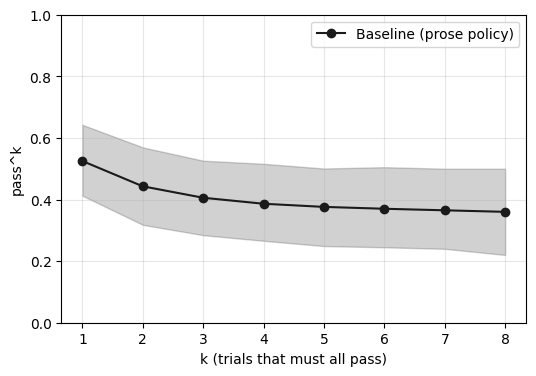

In [ ]:
# pass^k curve with 95% CI (Gemini baseline), saved to Drive
# runs on its own: mounts Drive and loads settings itself
import os, sys, csv, importlib
from google.colab import drive
drive.mount('/content/drive')
R = "/content/drive/MyDrive/cmsc691-10-project2"
sys.path.insert(0, R)
importlib.invalidate_caches()
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
import passk; importlib.reload(passk)
import settings_gemini; importlib.reload(settings_gemini)
from settings_gemini import MODEL, N_TASKS

n, rows = passk.curve(f"{R}/results_gemini_baseline", N_TASKS)
print(f"complete trials: {n}")
if rows:
    display(pd.DataFrame([{"k": r["k"], "pass^k": round(r["pass^k"], 3),
                           "95% CI": f"[{r['ci_low']:.2f}, {r['ci_high']:.2f}]"} for r in rows])
            .set_index("k").T)
    with open(f"{R}/results_gemini_baseline_passk.csv", "w", newline="") as f:
        w = csv.DictWriter(f, fieldnames=rows[0].keys()); w.writeheader(); w.writerows(rows)
    ks = [r["k"] for r in rows]
    plt.figure(figsize=(6, 4))
    # same black as the baseline in the 06G figure, so one arm has one color in the report
    plt.fill_between(ks, [r["ci_low"] for r in rows], [r["ci_high"] for r in rows], alpha=0.2, color="#1A1A1A")
    plt.plot(ks, [r["pass^k"] for r in rows], "o-", color="#1A1A1A", label="Baseline (prose policy)")
    plt.xlabel("k (trials that must all pass)"); plt.ylabel("pass^k")
    plt.ylim(0, 1); plt.xticks(ks); plt.grid(alpha=0.3); plt.legend()
    os.makedirs(f"{R}/figures", exist_ok=True)
    plt.savefig(f"{R}/figures/gemini_baseline_passk.png", dpi=200, bbox_inches="tight")
    plt.show()

In [ ]:
# which tasks are consistent? passes out of 8, per task
import importlib, passk; importlib.reload(passk)
tab = passk.table("/content/drive/MyDrive/cmsc691-10-project2/results_gemini_baseline")
full = {t: v for t, v in tab.items() if len(v) == N_TASKS}
c = passk.success_counts(full, range(N_TASKS))
always = [t for t, x in c.items() if x == len(full)]
never = [t for t, x in c.items() if x == 0]
some = [t for t, x in c.items() if 0 < x < len(full)]
print(f"trials: {len(full)}")
print(f"always pass ({len(always)}): {always}")
print(f"never pass  ({len(never)}): {never}")
print(f"sometimes   ({len(some)}): { {t: c[t] for t in some} }")

trials: 8
always pass (18): [1, 12, 13, 15, 18, 20, 21, 24, 27, 31, 35, 36, 38, 40, 42, 44, 48, 49]
never pass  (13): [8, 9, 10, 16, 19, 22, 23, 25, 32, 33, 34, 43, 46]
sometimes   (19): {0: 4, 2: 4, 3: 1, 4: 4, 5: 2, 6: 4, 7: 4, 11: 5, 14: 4, 17: 4, 26: 7, 28: 1, 29: 1, 30: 2, 37: 7, 39: 5, 41: 5, 45: 1, 47: 1}


In [ ]:
# find "sometimes pass, sometimes fail" tasks in the baseline, for the motivating figure (no API cost)
import os, sys, json
import pandas as pd
from IPython.display import display
R = "/content/drive/MyDrive/cmsc691-10-project2"
os.chdir(R); sys.path.insert(0, R)
import passk

tab = passk.table(f"{R}/results_gemini_baseline")          # {trial: {task: row}}
rows = []
for t in range(50):
    res = {tr: tab[tr][t]["reward"] >= 1 - 1e-6 for tr in sorted(tab) if t in tab[tr]}
    c = sum(res.values())
    rows.append({"task": t, "passed": f"{c}/{len(res)}",
                 "pass trials": " ".join(str(k) for k, v in res.items() if v),
                 "fail trials": " ".join(str(k) for k, v in res.items() if not v),
                 "type": "always pass" if c == len(res) else ("never pass" if c == 0 else "mixed")})
df = pd.DataFrame(rows)
display(df["type"].value_counts().to_frame("tasks"))
display(df[df["type"] == "mixed"].style.hide(axis="index").set_caption("Mixed tasks: pick one, compare a pass trial and a fail trial"))

,tasks
type,
mixed,19
always pass,18
never pass,13


task,passed,pass trials,fail trials,type
0,4/8,1 2 3 6,4 5 7 8,mixed
2,4/8,1 2 4 8,3 5 6 7,mixed
3,1/8,2,1 3 4 5 6 7 8,mixed
4,4/8,3 4 6 8,1 2 5 7,mixed
5,2/8,7 8,1 2 3 4 5 6,mixed
6,4/8,1 2 5 6,3 4 7 8,mixed
7,4/8,1 2 4 6,3 5 7 8,mixed
11,5/8,1 2 4 5 8,3 6 7,mixed
14,4/8,2 4 5 7,1 3 6 8,mixed
17,4/8,1 2 5 6,3 4 7 8,mixed


In [ ]:
# print one passing and one failing trial of the same task, turn by turn
TASK, PASS_TRIAL, FAIL_TRIAL = 14, 2, 1          # change these

def turns(trial):
    out = []
    for m in tab[trial][TASK]["traj"][1:]:          # skip the system prompt
        role = m.get("role")
        if role == "assistant" and m.get("tool_calls"):
            c = m["tool_calls"][0]["function"]
            out.append(("agent", f"CALL {c['name']}({c['arguments'][:120]})"))
        elif role == "tool":
            out.append(("tool", str(m.get("content"))[:120]))
        else:
            out.append((role, (m.get("content") or "")[:300]))
    return out

a, b = turns(PASS_TRIAL), turns(FAIL_TRIAL)
n = max(len(a), len(b))
side = pd.DataFrame({f"PASS (trial {PASS_TRIAL})": [f"{r}: {t}" for r, t in a] + [""] * (n - len(a)),
                     f"FAIL (trial {FAIL_TRIAL})": [f"{r}: {t}" for r, t in b] + [""] * (n - len(b))})
print("reward:", tab[PASS_TRIAL][TASK]["reward"], "vs", tab[FAIL_TRIAL][TASK]["reward"])
display(side.style.set_properties(**{"text-align": "left", "white-space": "pre-wrap"}).set_caption(f"Task {TASK}: same task, two trials"))

reward: 1.0 vs 0.0


,PASS (trial 2),FAIL (trial 1)
0,"user: Hi, I'm Chen Lee (ID: chen_lee_6825), and I'd like some help with my upcoming flight from Boston to Minneapolis, reservation YAX4DR.","user: Hi there, I have an upcoming flight from Boston to Minneapolis, reservation ID YAX4DR, and I'd like to make some changes to it."
1,"agent: CALL get_reservation_details({""reservation_id"": ""YAX4DR""})","agent: CALL get_reservation_details({""reservation_id"": ""YAX4DR""})"
2,"tool: {""reservation_id"": ""YAX4DR"", ""user_id"": ""chen_lee_6825"", ""origin"": ""BOS"", ""destination"": ""MSP"", ""flight_type"": ""one_way""","tool: {""reservation_id"": ""YAX4DR"", ""user_id"": ""chen_lee_6825"", ""origin"": ""BOS"", ""destination"": ""MSP"", ""flight_type"": ""one_way"""
3,"assistant: Hello Chen Lee, I see your reservation YAX4DR for a trip from Boston to Minneapolis. How can I assist you with this booking today?",assistant: I see your reservation YAX4DR from Boston to Minneapolis. Could you please tell me what changes you would like to make to your flight?
4,"user: I'd like to upgrade all passengers on this reservation to business class, and I also need to add two checked bags to my name using my Gold membership status.","user: I'd like to upgrade everyone on this reservation to business class, and I also need to add two checked bags under my name using my Gold membership."
5,"agent: CALL get_user_details({""user_id"": ""chen_lee_6825""})","agent: CALL get_user_details({""user_id"": ""chen_lee_6825""})"
6,"tool: {""name"": {""first_name"": ""Chen"", ""last_name"": ""Lee""}, ""address"": {""address1"": ""355 Hillcrest Drive"", ""address2"": ""Suite 3","tool: {""name"": {""first_name"": ""Chen"", ""last_name"": ""Lee""}, ""address"": {""address1"": ""355 Hillcrest Drive"", ""address2"": ""Suite 3"
7,"agent: CALL think({""thought"": ""The user wants to upgrade to business class and add two checked bags.\nReservation YAX4DR has 2 passengers.)",assistant:
8,tool:,user:
9,"assistant: I can certainly help you with that, Chen. To upgrade your reservation YAX4DR to business class, I will need to process the change. Since you are a Gold member, your new business class status will allow for 3 free checked bags per passenger, so adding two checked bags will be free of charge. Howeve","agent: CALL think({""thought"": ""The user wants to upgrade to business class and add two checked bags.\nReservation YAX4DR has 2 passengers.)"


In [ ]:
# motivating figure with short, verbatim excerpts ("…" only where words were left out); each piece is checked against the dialogue
def full_turns(trial):
    out = []
    for m in tab[trial][TASK]["traj"][1:]:
        role = m.get("role")
        if role == "assistant" and m.get("tool_calls"):
            c = m["tool_calls"][0]["function"]
            out.append(f"agent: CALL {c['name']}({c['arguments']})")
        elif role == "tool":
            out.append(f"tool: {m.get('content')}")
        else:
            out.append(f"{role}: {m.get('content') or ''}")
    return [t.replace("\\n", " ").replace("\n", " ") for t in out]

A_full, B_full = full_turns(PASS_TRIAL), full_turns(FAIL_TRIAL)

def excerpt(full, who, pieces):
    """Verbatim pieces joined by '…'; '…' only where words were really left out."""
    body = full.split(": ", 1)[1]
    for p in pieces:
        assert p in body, f"not in the dialogue: {p}"
    text = " … ".join(pieces)
    if not body.startswith(pieces[0]):
        text = "… " + text
    if not body.rstrip().endswith(pieces[-1]):
        text = text + " …"
    if "CALL think(" in body:
        who = "agent (thinking)"
    return f"{who}: {text}"

rows = [
    ("1. Budget",
     excerpt(A_full[10], "user", ["I have a budget of $600 for the upgrade costs for both of us"]),
     excerpt(B_full[12], "user", ["as long as it doesn't exceed $600 for the total change"])),
    ("2. Next move",
     excerpt(A_full[13], "agent", ["CALL search_direct_flight("]),
     excerpt(B_full[13], "agent", ["I don't have a direct tool to get the price difference"])),
    ("3. Result",
     excerpt(A_full[23], "agent", ["the total cost for both you and Noah would be $1,200", "Since this exceeds your $600 budget"]),
     excerpt(B_full[21], "agent", ["The total charge for the upgrade was $1,200"])),
    ("4. End",
     excerpt(A_full[25], "agent", ["CALL update_reservation_baggages(", '"total_baggages": 2']),
     excerpt(B_full[22], "user", ["I was only willing to pay up to $600", "could you please revert the changes for me?"])),
]
fig = pd.DataFrame(rows, columns=["step", f"PASS (trial {PASS_TRIAL})", f"FAIL (trial {FAIL_TRIAL})"])
display(fig.style.hide(axis="index")
        .set_properties(**{"text-align": "left", "white-space": "pre-wrap", "font-size": "14px",
                           "vertical-align": "top", "word-break": "break-word", "padding": "6px"})
        .set_table_styles([{"selector": "", "props": "table-layout: fixed; width: 480px;"},
                           {"selector": "th", "props": "text-align: center; background-color: #f2f2f2; font-size: 14px;"},
                           {"selector": "th:nth-child(1), td:nth-child(1)", "props": "width: 70px; font-weight: bold;"},
                           {"selector": "caption", "props": "font-size: 14px; font-weight: bold; padding-bottom: 6px;"}])
        .set_caption(f"Task {TASK}: same task, two trials (reward 1.0 vs 0.0)"))

step,PASS (trial 2),FAIL (trial 1)
1. Budget,user: … I have a budget of $600 for the upgrade costs for both of us …,user: … as long as it doesn't exceed $600 for the total change …
2. Next move,agent: CALL search_direct_flight( …,agent (thinking): … I don't have a direct tool to get the price difference …
3. Result,"agent: … the total cost for both you and Noah would be $1,200 … Since this exceeds your $600 budget …","agent: … The total charge for the upgrade was $1,200 …"
4. End,"agent: CALL update_reservation_baggages( … ""total_baggages"": 2 …",user: … I was only willing to pay up to $600 … could you please revert the changes for me?


## Summary

**Results**
- Model: `gemini-3.1-flash-lite` (agent and user), paid Gemini API ; complete trials: 8 / 8 ; API errors left: 0
- pass^1: 0.525 [CI 0.41, 0.64] ; pass^8: 0.360 [CI 0.22, 0.50]
- Always / never / sometimes: 18 / 13 / 19
- Per dialogue: about 29 calls, about 142k input tokens (from the 10-task pilot) ; time per trial: 5–42 min at concurrency 4
- Cost: about $8 for the pilots and all 400 dialogues (prepaid credits: $20 → $12.20)

| k | pass^k | 95% CI |
|---|---|---|
| 1 | 0.525 | [0.41, 0.64] |
| 2 | 0.443 | [0.32, 0.57] |
| 3 | 0.406 | [0.28, 0.53] |
| 4 | 0.386 | [0.27, 0.52] |
| 5 | 0.376 | [0.25, 0.50] |
| 6 | 0.370 | [0.24, 0.51] |
| 7 | 0.365 | [0.24, 0.50] |
| 8 | 0.360 | [0.22, 0.50] |

**Analysis**
- pass^1 = 52.5%, about twice the paper's 26.0% for gemini-1.5-flash on airline. The two numbers are not directly comparable: both the agent model and the user simulator are different (the paper used gpt-4-0613 as the user; I used gemini-3.1-flash-lite).
- The curve drops from 0.525 to 0.360 (about 31%). The agent solves about half the tasks, but only about a third every time.
- 19 tasks pass sometimes and fail sometimes. This is where KiL can help.
- 13 tasks never pass. Look at them separately when comparing arms.

**Notes**
- The pilot folder has two runs (two sessions ran at the same time), so the pilot table showed doubled calls and cost. The numbers above are divided by 2.
- Two old `gemini-3.5-flash` files (free-key test, all errors) were in trials 3 and 8. τ-bench rows with errors are replaced by the rerun, so they don't count. I moved them to `results_gemini_baseline_old_3.5flash/`.

**Files**
- `results_gemini_baseline/trial_1..8/`: raw results
- `results_gemini_baseline_passk.csv`, `figures/gemini_baseline_passk.png`

**Next:** 06G, the validator on Gemini (same `policy_checker.py`, only the model changes).